# Experiment 4 · Random-start trials in the seed without a centre pull

**Date:** 2026-11-07 · **Agents:** `baseline_s8` (and `baseline_s1` for comparison) · **Status:** observation (2 seeds, 10 trials each)

## Question
Experiment 3 found that `baseline_s8` is the only seed with no centre pull: its hold drift
goes towards the target, not towards x = 0. Does that show up in the actual random-start
trials, and does s8 avoid the false starts that s1 had in Experiment 2?

## Design
Exactly the trials of Experiment 2 (same random-start seed, so the same starts, targets and
go cues), run on `baseline_s8`, and compared trial by trial with `baseline_s1`. Hold rule
relative to the new start, noiseless plant, mean action.

In [1]:
from exp_tools import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Video, display
from single_target_video import make_video, outcome

use_style()
pd.set_option("display.precision", 3)

In [2]:
out, traj8, infos8 = make_video(RUNS / "baseline_s8", trials=10, seed=0, start_range=0.9,
                                fmt="mp4", name="exp04_random_start_s8")
print(f"video: {out}")
display(Video(rel(out), embed=False, width=820))

video: /Users/aghavamp/Desktop/Projects/SeqHorizon_basic/1D/runs/baseline_s8/videos/exp04_random_start_s8.mp4


## Trial-by-trial comparison with s1

For each trial: the hold-period displacement up to the go cue (or the false start), and whether it went towards the target or towards the centre. In *outward* trials those two directions are opposite.

In [3]:
_, traj1, infos1 = make_video(RUNS / "baseline_s1", trials=10, seed=0, start_range=0.9,
                              fmt="mp4", name="exp02_random_start")

def hold_rows(traj, infos, seed):
    rows = []
    for i, d in enumerate(infos):
        n = min(d["go"], d["T"])
        dx = traj["x"][n - 1, i] - d["start"]
        rows.append({"trial": i + 1, "seed": seed, "start": d["start"], "target": d["target"],
                     "dist": abs(d["target"] - d["start"]),
                     "side": target_side(d["start"], d["target"]),
                     "hold moved": dx,
                     "to target": np.sign(dx) == np.sign(d["target"] - d["start"]),
                     "to centre": np.sign(dx) == -np.sign(d["start"]),
                     "v@0.1s": traj["v"][5, i], "v@end": traj["v"][n - 1, i],
                     "outcome": outcome(d)})
    return rows

cmp = pd.DataFrame(hold_rows(traj1, infos1, 1) + hold_rows(traj8, infos8, 8))
cmp.pivot(index=["trial", "start", "target", "dist", "side"], columns="seed",
          values=["hold moved", "outcome"])

hold moved             outcome             
seed                                       1      8            1            8
trial start  target dist  side                                               
1      0.247  0.776 0.529 outward     -0.035   0.01           ok           ok
2     -0.414 -0.827 0.413 outward      0.097 -0.063           ok           ok
3     -0.826  0.418 1.244 inward       0.157   0.08  FALSE START           ok
4     -0.870  0.206 1.076 inward       0.068   0.02           ok           ok
5      0.564 -0.849 1.413 inward      -0.156 -0.154  FALSE START  FALSE START
6      0.743  0.395 0.348 inward      -0.156 -0.012  FALSE START           ok
7      0.192 -0.871 1.063 inward      -0.015 -0.015           ok           ok
8      0.413 -0.781 1.194 inward       -0.13 -0.073           ok           ok
9      0.079  0.614 0.536 outward     -0.005  0.009           ok           ok
10     0.783 -0.780 1.563 inward      -0.158 -0.154  FALSE START  FALSE START

In [4]:
print("outward trials (centre and target in opposite directions):")
display(cmp[cmp.side == "outward"][["trial", "seed", "start", "target", "hold moved", "to target", "to centre"]])
print("false starts:")
display(cmp[cmp.outcome == "FALSE START"][["trial", "seed", "start", "target", "dist", "side", "v@0.1s", "v@end"]])

outward trials (centre and target in opposite directions):


,trial,seed,start,target,hold moved,to target,to centre
0,1,1,0.247,0.776,-0.035,False,True
1,2,1,-0.414,-0.827,0.097,False,True
8,9,1,0.079,0.614,-0.005,False,True
10,1,8,0.247,0.776,0.010,True,False
11,2,8,-0.414,-0.827,-0.063,True,False
18,9,8,0.079,0.614,0.009,True,False


false starts:


,trial,seed,start,target,dist,side,v@0.1s,v@end
2,3,1,-0.826,0.418,1.244,inward,0.302,0.385
4,5,1,0.564,-0.849,1.413,inward,-0.243,-0.328
5,6,1,0.743,0.395,0.348,inward,-0.214,-0.325
9,10,1,0.783,-0.780,1.563,inward,-0.347,-0.506
14,5,8,0.564,-0.849,1.413,inward,-0.129,-0.189
19,10,8,0.783,-0.780,1.563,inward,-0.164,-0.257


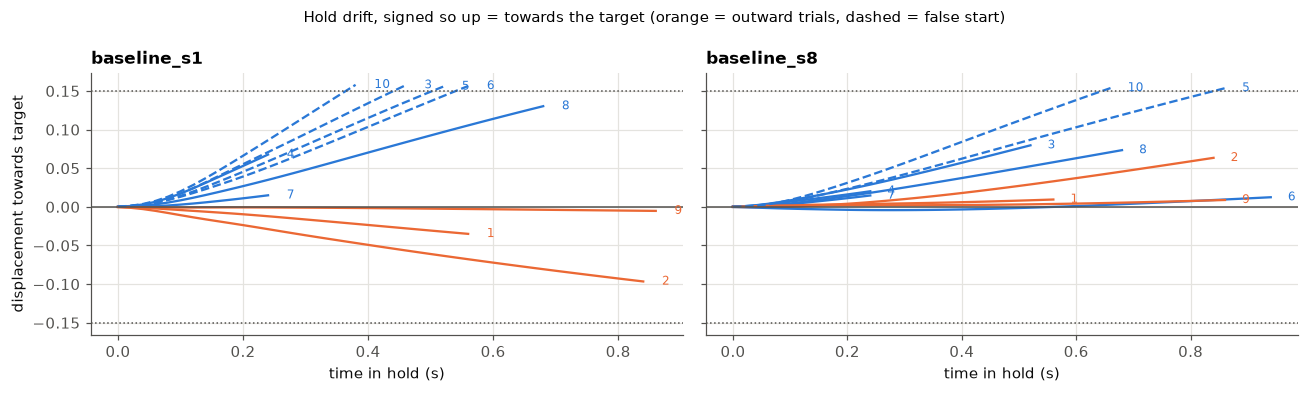

In [5]:
dt = traj8["dt"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (traj, infos, s) in zip(axs, [(traj1, infos1, 1), (traj8, infos8, 8)]):
    for i, d in enumerate(infos):
        n = min(d["go"], d["T"])
        side = target_side(d["start"], d["target"])
        # sign so that + = towards the target
        sg = np.sign(d["target"] - d["start"])
        style = dict(color=ORANGE if side == "outward" else BLUE, ls="-" if d["success"] else "--")
        ax.plot(np.arange(n) * dt, sg * (traj["x"][:n, i] - d["start"]), lw=1.5, **style)
        ax.text(n * dt + 0.01, sg * (traj["x"][n - 1, i] - d["start"]), str(i + 1), fontsize=8,
                color=style["color"], va="center")
    ax.axhline(0, color=INK_SOFT, lw=1)
    ax.axhline(0.15, color=INK_SOFT, ls=":", lw=1); ax.axhline(-0.15, color=INK_SOFT, ls=":", lw=1)
    ax.set_title(f"baseline_s{s}"); ax.set_xlabel("time in hold (s)")
axs[0].set_ylabel("displacement towards target")
fig.suptitle("Hold drift, signed so up = towards the target (orange = outward trials, dashed = false start)", fontsize=10)
plt.tight_layout(); plt.show()

## Conclusion

**s8 really has no centre pull: its hold drift goes towards the target in all 10 trials.** In
the three outward trials (1, 2 and 9), where s1 drifted towards the centre and away from the
target, s8 drifts towards the target instead. This confirms the Experiment 3 classification
on real task trials.

**But s8 still has 2 false starts (trials 5 and 10), against s1's 4, from a different cause:
the target pull.**
- Both are the two **longest** reaches in the set (start-to-target distance 1.41 and 1.56),
  with the target across the centre.
- The drift in those trials **speeds up during the hold** (trial 10: 0.16 at 0.1 s, 0.26 at
  0.68 s), so with a long enough hold it crosses the 0.15 limit.
- Experiment 3 used offsets of at most 0.4, so it never tested targets this far away, and its
  "safe within ±0.4" rule only covers the centre pull. **Far targets are a separate risk**,
  from the target pull, in seeds where that pull is strong.
- s1's false starts include trial 6, a short inward reach (distance 0.35), which is the centre
  pull. Trials 5 and 10 fail in both seeds, where centre and target point the same way, so
  each seed fails there for its own reason.

**Revised picture:** off the trained start, the hold drift has two components, a pull towards
the centre and a pull towards the target, mixed in different proportions per seed. Either one
can push the mass past the abort line if it is strong enough and the hold is long enough. A
centre-start trial (Experiment 1) only shows the target component.

*Limits: 10 trials per seed, 2 seeds, noiseless plant. Whether the target pull grows with
distance more than linearly (as trials 5 and 10 suggest) has not been tested.*